In [1]:
# import necessary libraries

import matplotlib.pyplot as plt
import numpy as np
from scipy.optimize import curve_fit
from scipy import stats 
import sympy as sym # for integration but i didn't need it anymore

%matplotlib inline
import matplotlib.patches as mpatches

import pandas as pd
import matplotlib.dates as mdates

In [2]:
# input data

volumes = np.linspace(0.04, 0.20, 9)
print(volumes)

vrc_change_in_force = [2.04, 2.26, 2.43, 2.57, 2.63, 2.7, 2.78, 2.82, 2.92]

[0.04 0.06 0.08 0.1  0.12 0.14 0.16 0.18 0.2 ]


line of best fit: y = 1.218x + 3.753


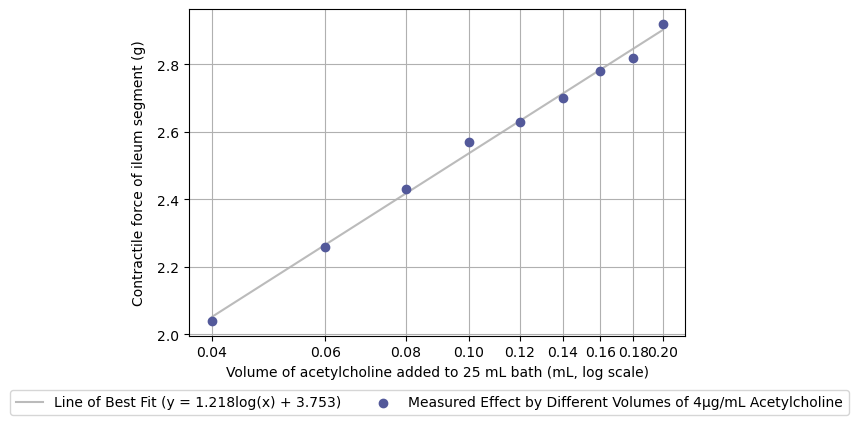

In [3]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.ticker import ScalarFormatter, NullFormatter
from matplotlib.ticker import MultipleLocator

volumes = np.asarray(volumes)

fig, ax = plt.subplots()


# line of best fit: fit in log space, then draw it over the raw volumes
slope, intercept = np.polyfit(np.log10(volumes), vrc_change_in_force, 1)
x_fit = np.logspace(np.log10(volumes.min()), np.log10(volumes.max()), 100)
y_fit = slope * np.log10(x_fit) + intercept
print(f"line of best fit: y = {slope:.3f}x + {intercept:.3f}")
ax.plot(x_fit, y_fit, label="Line of Best Fit (y = 1.218log(x) + 3.753)", color='#bbbbbb', zorder=1)

ax.scatter(volumes, vrc_change_in_force, color='#53599A',
           label="Measured Effect by Different Volumes of 4μg/mL Acetylcholine", zorder=2)

# log x-axis with normal volume labels
ax.set_xscale("log")
ax.set_xticks(np.unique(volumes))
ax.xaxis.set_major_formatter(ScalarFormatter())
ax.xaxis.set_minor_formatter(NullFormatter())
ax.tick_params(axis="x", which="minor", length=0)

# axes titles
ax.set_ylabel("Contractile force of ileum segment (g)", fontsize=10, labelpad=8)
ax.set_xlabel("Volume of acetylcholine added to 25 mL bath (mL, log scale)", fontsize=10)

# push the bottom edge of the plot upward to clear dedicated space
fig.subplots_adjust(bottom=0.2)

# attach the legend to the figure canvas
fig.legend(
    loc="lower center",
    bbox_to_anchor=(0.5, 0.02),
    ncols=2,
    frameon=True,
)

ax.grid(True, which="major")
plt.show()

In [4]:
# input data
x_labels = ["Low response (0.06 mL)", "High response (0.18 mL)"]
x_positions = [0, 1]  # numeric positions for the two categories

standard_means = [2.5275, 2.9175]   # [low, high]
standard_ses   = [0.07847504911/np.sqrt(4), 0.03862210075/np.sqrt(4)]

unknown_means  = [2.44, 2.9]   # [low, high]
unknown_ses    = [0.02943920289/np.sqrt(4), 0.1070825227]


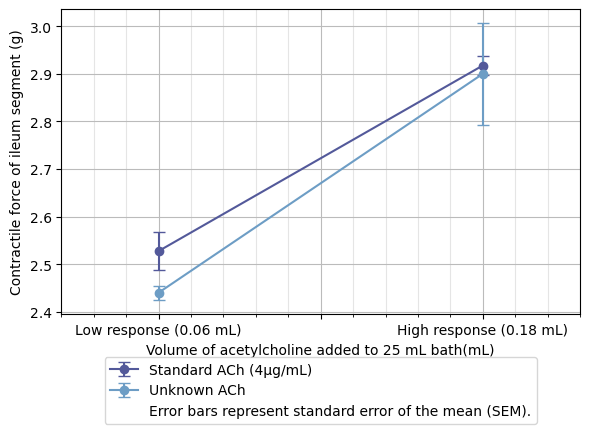

In [5]:
# create plot

fig, ax = plt.subplots(figsize=(6, 4.5))

ax.errorbar(
    x_positions, standard_means, yerr=standard_ses,
    marker="o", linestyle="-", color="#53599A", capsize=4, label="Standard ACh (4μg/mL)"
)
ax.errorbar(
    x_positions, unknown_means, yerr=unknown_ses,
    marker="o", linestyle="-", color="#6D9DC5", capsize=4, label="Unknown ACh"
)

# including extra text in legend
ax.errorbar([], [], yerr=0, color="w", alpha=0, label="Error bars represent standard error of the mean (SEM).")
ax.set_xticks(x_positions)
ax.set_xticklabels(x_labels)
ax.set_xlim(-0.3, 1.3)  # padding so points and error bars aren't cut off
ax.set_ylabel("Contractile force of ileum segment (g)")
ax.set_xlabel("Volume of acetylcholine added to 25 mL bath(mL)")


# legend below the plot
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.12), ncol=1, frameon=True)

plt.tight_layout()
plt.grid(True)
# place a major gridline every 0.5 units, and a minor line every 0.1 units
ax.xaxis.set_major_locator(MultipleLocator(0.5))
ax.xaxis.set_minor_locator(MultipleLocator(0.1))

# Enable both grids
ax.grid(which='major', color='#bbbbbb', linestyle='-')
ax.grid(which='minor', color='#cccccc', linestyle='-', alpha=0.5)
plt.show()

In [6]:
# finding average Δeffect for all values between 2 lines (we approximate parallel lines)

# denoting x
x = sym.Symbol('x')
# equation of lines
y_unknown = ((2.9-2.44)/np.log10(3))*(x-np.log10(0.18))+2.9
y_standard = ((2.9175-2.5275)/np.log10(3))*(x-np.log10(0.18))+2.9175

f = y_standard - y_unknown

avg_difference = sym.integrate(f, (x, -1.2218487496, -0.7447274949))/(np.log10(0.18)-np.log10(0.06))
print("average difference =", avg_difference)

# i don't think this is right
# potency_ratio = (np.mean(standard_means)-avg_difference)/np.mean(standard_means)
# print("potency ratio =", potency_ratio)

# concentration = potency_ratio*4 # μg/mL ACh
# print("concentration =", concentration)

average difference = 0.0524999999968790


In [7]:

# calculate potency ratio
vol_low, vol_high = 0.06, 0.18   # mL
std_conc = 4                     # µg/mL

log_ratio = np.log10(vol_high / vol_low)

slope_std = (standard_means[1] - standard_means[0]) / log_ratio
slope_unk = (unknown_means[1] - unknown_means[0]) / log_ratio
b = (slope_std + slope_unk) / 2 # assume parallelism

diff = np.mean(unknown_means) - np.mean(standard_means)
potency_ratio = 10 ** (diff / b)

unknown_conc = potency_ratio * std_conc
print(f"potency ratio = {potency_ratio:.3f}")
print(f"unknown concentration = {unknown_conc:.2f} µg/mL")
print(f"b = {b:.3f}")
print(f"diff = {diff:.3f}")
print(f"slope of standard = {slope_std:.3f}")
print(f"slope of unknown = {slope_unk:.3f}")

potency ratio = 0.873
unknown concentration = 3.49 µg/mL
b = 0.891
diff = -0.053
slope of standard = 0.817
slope of unknown = 0.964


In [8]:

n = 4  # replicates per measurement

S = np.array([2.5275, 2.9175]);  S_sd = np.array([0.07847504911, 0.03862210075])
U = np.array([2.44,   2.9   ]);  U_sd = np.array([0.02943920289, 0.1070825227])
std_conc = 4 # µg/mL
denom = np.log10(0.18 / 0.06)

def log_potency(sL, sH, uL, uH):
    return denom * (uL + uH - sL - sH) / ((sH - sL) + (uH - uL))

vals = np.array([*S, *U]) # sL, sH, uL, uH
sems = np.array([*S_sd, *U_sd]) / np.sqrt(n)

# numerical gradient of log R with respect to each mean
grad = np.zeros(4)
h = 1e-6
for i in range(4):
    up, dn = vals.copy(), vals.copy()
    up[i] += h; dn[i] -= h
    grad[i] = (log_potency(*up) - log_potency(*dn)) / (2 * h)

# propagate SEMs (delta method)
terms = (grad * sems) ** 2
logR = log_potency(*vals)
logR_se = np.sqrt(terms.sum())

# Welch-Satterthwaite effective degrees of freedom (from claude ai), then t critical value
df = terms.sum() ** 2 / np.sum(terms ** 2 / (n - 1))
t_crit = stats.t.ppf(0.975, df)

R = 10 ** logR
conc = R * std_conc
conc_se = conc * np.log(10) * logR_se
lo = 10 ** (logR - t_crit * logR_se) * std_conc
hi = 10 ** (logR + t_crit * logR_se) * std_conc

print(f"log R = {logR:.4f} ± {logR_se:.4f} (SEM)")
print(f"concentration = {conc:.2f} ± {conc_se:.2f} µg/mL (SEM)")
print(f"df ≈ {df:.1f}, t = {t_crit:.3f}")
print(f"95% CI: {lo:.2f} to {hi:.2f} µg/mL")

# parallelism check
diff = (U[1] - U[0]) - (S[1] - S[0])
diff_se = np.sqrt(np.sum(sems ** 2))
print(f"slope-difference t-ratio: {diff / diff_se:.2f}")

p = 2 * stats.t.sf(0.99, 7)
print(p)

log R = -0.0589 ± 0.0435 (SEM)
concentration = 3.49 ± 0.35 µg/mL (SEM)
df ≈ 6.4, t = 2.411
95% CI: 2.74 to 4.45 µg/mL
slope-difference t-ratio: 0.99
0.35515274716978484


In [9]:
# input data for bracket method
bracket_x_volumes = [0.05, 0.10, 0.15]  # numeric positions for the two categories

bracket_standards = [2.36, 2.705, 2.9]   # [0.05, 0.10, 0.15]
bracket_standard_ses   = [0, 0.1202081528/np.sqrt(4), 0]

bracket_unknown_volumes  = [0.0552301216751, 0.107982654655]   # [0.10, 0.15]
bracket_unknown_means = [2.41, 2.74]

labels = ['0.10mL', '0.15mL']

x = np.linspace(0.05, 0.15, 300)
line_obf = 1.13333*np.log10(x)+3.83552

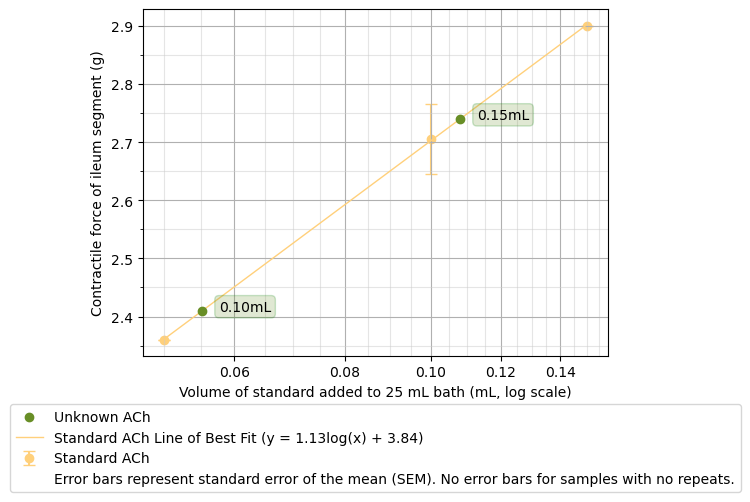

In [10]:
# create plot

fig, ax = plt.subplots(figsize=(6, 4.5))

ax.scatter(
    bracket_unknown_volumes, bracket_unknown_means,
    marker="o", linestyle="-", color="#688E26", label="Unknown ACh",  zorder=3
)
ax.errorbar(
    bracket_x_volumes, bracket_standards, yerr=bracket_standard_ses,
    marker="o", linestyle="", color="#FFD07B", capsize=4, label="Standard ACh",  zorder=1
)

ax.plot(x, line_obf, color="#FFD07B", label="Standard ACh Line of Best Fit (y = 1.13log(x) + 3.84)", linewidth=1, zorder=2)

# set box for annotations
box_style = dict(
    boxstyle='round,pad=0.3',      # Shape of the box ('square', 'round', 'sawtooth', etc.)
    facecolor='#688E26',             # Background colour
    edgecolor='green',            # Border colour
    alpha=0.2                      # Transparency (0 to 1)
)

# annotate unknowns
for i, txt in enumerate(labels):
    plt.annotate(
        txt,
        (bracket_unknown_volumes[i], bracket_unknown_means[i]),
        textcoords="offset points",
        xytext=(12, 0),
        ha='left',
        bbox=box_style,
        zorder=5
    )

# log scale
ax.set_xscale("log")
ax.set_xticks(np.unique(volumes))
ax.xaxis.set_major_formatter(ScalarFormatter())
ax.xaxis.set_minor_formatter(NullFormatter())
ax.tick_params(axis="x", which="minor", length=0)
# including extra text in legend
ax.errorbar([], [], yerr=0, color="w", alpha=0, label="Error bars represent standard error of the mean (SEM). No error bars for samples with no repeats.")

# ax.set_xlim(0, 0.2)  # padding so points and error bars aren't cut off
ax.set_ylabel("Contractile force of ileum segment (g)")
ax.set_xlabel("Volume of standard added to 25 mL bath (mL, log scale)")


# legend below the plot
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.12), ncol=1, frameon=True)

# plt.tight_layout()
plt.grid(True)
# place a major gridline every 0.5 units, and a minor line every 0.1 units
ax.xaxis.set_minor_locator(MultipleLocator(0.005))
ax.yaxis.set_minor_locator(MultipleLocator(0.05))

# Enable both grids
# ax.grid(which='major', color='#bbbbbb', linestyle='-')
ax.grid(which='minor', color='#cccccc', linestyle='-', alpha=0.5)
plt.show()

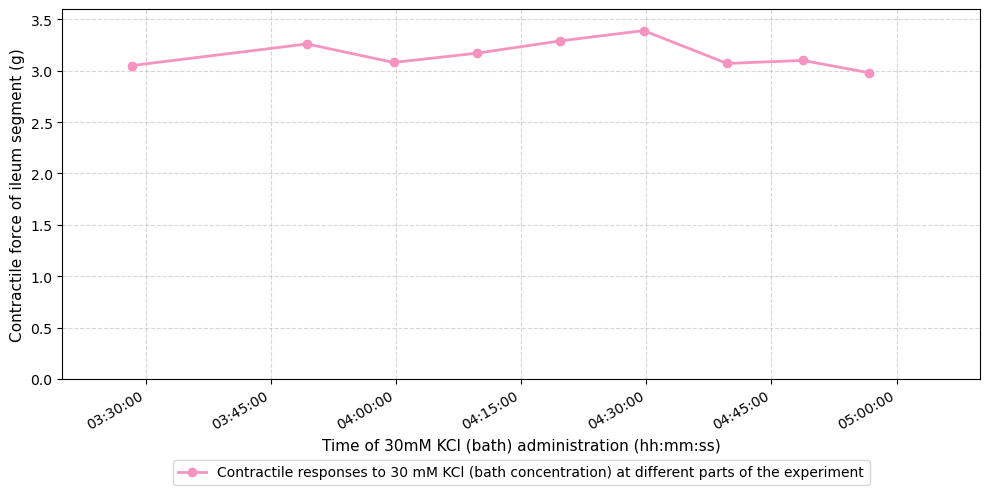

In [11]:
# input data
data = {
    'timestamp': ['03:28:22', '03:49:19', '03:59:42', '04:09:41', '04:19:42', '04:29:41', '04:39:41', '04:48:44', '04:56:42'],
    'force': [3.05, 3.26, 3.08, 3.17, 3.29, 3.39, 3.07, 3.1, 2.98],
    'label': ['Before ACh VRC', 'After ACh VRC', 'Volumetric Analysis Bioassay Test–Round 1', 'Round 2', 'Round 3', 'Round 4', '0.10 mL bracket', '0.15 mL bracket', 'End of experiment']

}
df = pd.DataFrame(data)

# convert timestamps into datetime objects
df['actual_time'] = pd.to_datetime(df['timestamp'], format='%H:%M:%S')

# create plot
fig, ax = plt.subplots(figsize=(10, 5))
ax.plot(df['actual_time'], df['force'], marker='o', color='#F694C1', linewidth=2, label='Contractile responses to 30 mM KCl (bath concentration) at different parts of the experiment')

# hide the background date and format X-axis to only show time
ax.xaxis.set_major_formatter(mdates.DateFormatter('%H:%M:%S'))

# clean up layout by auto-rotating the timestamp labels
fig.autofmt_xdate()


# labels
ax.set_xlim(pd.to_datetime(['03:20:00'], format='%H:%M:%S'),pd.to_datetime(['5:10:00'], format='%H:%M:%S'))  # padding so points and error bars aren't cut off
ax.set_ylim(0, 3.6)
ax.set_xlabel('Time of 30mM KCl (bath) administration (hh:mm:ss)', fontsize=11)
ax.set_ylabel('Contractile force of ileum segment (g)', fontsize=11)
ax.grid(True, linestyle='--', alpha=0.5)

plt.legend(loc='upper center', bbox_to_anchor=(0.5, -0.20), shadow=False, frameon=True, facecolor='white')

plt.tight_layout()
plt.show()
